<a href="https://colab.research.google.com/github/Luiseg-ds/analisis-predictivo-PAES/blob/main/An%C3%A1lisis_Exploratorio_de_Datos_Resultados_PAES.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install faker

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 26.2 MB/s eta 0:00:00


# 📊 Data Science Aplicado a la Educación: Análisis Predictivo de Resultados PAES

La toma de decisiones basada en datos representa el próximo gran avance para la gestión escolar y el acompañamiento pedagógico en Chile. Históricamente, las instituciones educativas acumulan una inmensa cantidad de información sobre sus estudiantes (calificaciones, asistencia, ensayos), pero rara vez se utiliza esta data en todo su potencial para proyectar escenarios y diseñar intervenciones tempranas.

Este proyecto desarrolla un modelo analítico y predictivo centrado en el proceso de Admisión a la Educación Superior. Su objetivo es demostrar cómo las herramientas de *Machine Learning* y el Análisis Exploratorio de Datos (EDA) pueden transformar el historial académico en información estratégica de alto valor para directivos, docentes y equipos de orientación.

## 🎯 Objetivos del Proyecto

* **Modelamiento de Entornos Realistas:** Construcción de un conjunto de datos que respeta rigurosamente las reglas matemáticas y de ponderación del sistema de admisión chileno (DEMRE), reflejando el comportamiento estadístico de una cohorte de estudiantes de IV° Medio.
* **Identificación de Factores Críticos:** Analizar y visualizar la correlación entre variables de proceso (asistencia, evolución del puntaje en ensayos) y factores estructurales (NEM, Puntaje Ranking, variables sociodemográficas).
* **Proyección y Alerta Temprana:** Sentar las bases para un modelo predictivo capaz de estimar el rendimiento final en la prueba PAES de Competencia Matemática 1 (M1), permitiendo a los colegios focalizar sus recursos en los estudiantes que más lo necesitan *antes* de la rendición oficial.

## 🗂️ Arquitectura de los Datos

Para lograr un análisis integral, el modelo captura la trayectoria del estudiante a través de múltiples dimensiones:

* **Historial Académico Oficial:** Nota de Enseñanza Media (NEM), conversión a Puntaje NEM (escala 100-1000) y cálculo del Puntaje Ranking bonificado según el contexto del establecimiento.
* **Evaluación Continua:** Rendimiento progresivo a través de 8 ensayos estandarizados durante el año, contemplando el ausentismo (tratamiento de datos nulos).
* **Contexto y Hábitos:** Porcentaje de asistencia a clases, género y preparación paralela (preuniversitario externo).

---

*A continuación, se inicializa el motor de simulación para estructurar la base de datos de la cohorte, dando paso a la fase de Análisis Exploratorio de Datos (EDA) para descubrir los patrones de rendimiento.*

---

Copia este texto en la primera celda de tu cuaderno y cámbiala de "Code" a "Markdown". Quedará como una presentación de altísimo nivel, ideal para que cualquier reclutador o líder educativo entienda de inmediato el valor de tu trabajo.

¿Iniciamos con el código del EDA y el mapa de calor (Heatmap) en la siguiente celda?

In [ ]:
import pandas as pd
import numpy as np
import random

# 1. Configuración Inicial y Visualización
pd.set_option('display.max_columns', None) # Evita que pandas oculte columnas
pd.set_option('display.width', 1000)
num_estudiantes = 109
np.random.seed(42)
random.seed(42)

# 2. Creación del DataFrame
df = pd.DataFrame()
df['ID_Estudiante'] = [f"EST_{i:03d}" for i in range(1, num_estudiantes + 1)]

# 3. Simulación del Target (PAES M1 Real)
tramos_paes = [
    (450, 499, 1), (550, 599, 3), (600, 649, 5), (650, 699, 8), (700, 749, 3),
    (750, 799, 9), (800, 849, 10), (850, 899, 12), (900, 949, 29), (950, 1000, 29)
]

puntajes_paes = []
for min_p, max_p, cantidad in tramos_paes:
    puntajes_paes.extend(np.random.randint(min_p, max_p + 1, cantidad))

np.random.shuffle(puntajes_paes)
df['PAES_M1_Real'] = puntajes_paes

# 4. Variables Categóricas
df['Genero'] = np.random.choice(['Femenino', 'Masculino'], size=num_estudiantes, p=[0.52, 0.48])
prob_preu = np.where(df['PAES_M1_Real'] >= 850, 0.8, 0.4)
df['Preuniversitario'] = [np.random.choice(['Sí', 'No'], p=[p, 1-p]) for p in prob_preu]

# 5. Variables Continuas y Cálculo NEM
df['Nota_NEM'] = df['PAES_M1_Real'] * 0.0028 + 4.2 + np.random.normal(0, 0.25, num_estudiantes)
df['Nota_NEM'] = df['Nota_NEM'].clip(4.0, 7.0).round(2)

def calcular_puntaje_nem(nota):
    if nota < 4.0: return 100
    elif nota < 5.0: return 100 + (nota - 4.0) * 315
    elif nota < 6.0: return 415 + (nota - 5.0) * 298
    elif nota <= 7.0: return 713 + (nota - 6.0) * 287
    else: return 1000

df['Puntaje_NEM'] = df['Nota_NEM'].apply(calcular_puntaje_nem).astype(int)

# 6. Cálculo del Puntaje Ranking
def calcular_ranking(row):
    bonificacion = (row['Nota_NEM'] - 5.4) * 110 + np.random.normal(0, 10)
    ranking_calc = row['Puntaje_NEM'] + bonificacion
    return int(np.clip(ranking_calc, 150, 1000))

df['Puntaje_Ranking'] = df.apply(calcular_ranking, axis=1)

df['Asistencia_Pct'] = df['PAES_M1_Real'] * 0.03 + 65 + np.random.normal(0, 5, num_estudiantes)
df['Asistencia_Pct'] = df['Asistencia_Pct'].clip(60, 100).round(1)

# 7. Ensayos con Datos Nulos (NaN)
for i in range(1, 9):
    factor_crecimiento = 0.75 + (i * 0.03)
    puntaje_ensayo = df['PAES_M1_Real'] * factor_crecimiento + np.random.normal(0, 40, num_estudiantes)
    puntaje_ensayo = np.clip(puntaje_ensayo, 150, 1000)

    ausencias = np.random.choice([True, False], size=num_estudiantes, p=[0.15, 0.85])
    puntaje_ensayo[ausencias] = np.nan

    df[f'Ensayo_{i}'] = np.round(puntaje_ensayo)

# 8. Reordenar columnas de forma profesional y exportar
columnas_ordenadas = ['ID_Estudiante', 'Genero', 'Preuniversitario',
                      'Nota_NEM', 'Puntaje_NEM', 'Puntaje_Ranking', 'Asistencia_Pct',
                      'Ensayo_1', 'Ensayo_2', 'Ensayo_3', 'Ensayo_4',
                      'Ensayo_5', 'Ensayo_6', 'Ensayo_7', 'Ensayo_8', 'PAES_M1_Real']

df = df[columnas_ordenadas]

nombre_archivo = 'dataset_paes_simulado_final.csv'
df.to_csv(nombre_archivo, index=False)
print(f"¡Dataset guardado como: {nombre_archivo}!\n")

# Mostrar un vistazo con TODAS las columnas visibles
print(df.head(10))

¡Dataset guardado como: dataset_paes_simulado_final.csv!

  ID_Estudiante     Genero Preuniversitario  Nota_NEM  Puntaje_NEM  Puntaje_Ranking  Asistencia_Pct  Ensayo_1  Ensayo_2  Ensayo_3  Ensayo_4  Ensayo_5  Ensayo_6  Ensayo_7  Ensayo_8  PAES_M1_Real
0       EST_001   Femenino               Sí      5.90          683              741            82.7     526.0     510.0     460.0     606.0     575.0     611.0     622.0       NaN           652
1       EST_002  Masculino               No      6.10          741              814            82.7     525.0     593.0     513.0       NaN     624.0     679.0     618.0     616.0           660
2       EST_003   Femenino               No      7.00         1000             1000            89.5     700.0     838.0     782.0     809.0     884.0     902.0     892.0     980.0           956
3       EST_004  Masculino               Sí      6.76          931             1000            91.0     693.0     754.0     829.0     778.0     827.0     880.0     86

**1. Importación de librerías y carga del dataset**

En el RISE se introduce la idea de que el EDA comienza con una revisión ordenada del dataset.
Aquí empezamos cargando las librerías necesarias y el conjunto de datos tips, incluido en Seaborn.

Trabajaremos con:

pandas para manipulación de datos,

numpy para apoyo numérico,

seaborn y matplotlib para visualización.

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Configuración visual base
sns.set_theme(style="whitegrid")

# Carga del dataset oficial del proyecto PAES
df = pd.read_csv('dataset_paes_simulado_final.csv')

**2. Inspección inicial del dataset**

Un EDA mínimo viable no empieza haciendo gráficos sin contexto.
Antes conviene responder preguntas básicas:

¿Cuántas filas y columnas tiene el dataset?

¿Qué tipo de variables contiene?

¿Hay valores nulos?

¿Qué representa cada columna?

Esta inspección inicial nos da una primera imagen del conjunto de datos y permite detectar problemas evidentes antes de profundizar.

In [ ]:
# Dimensiones del dataset (filas, columnas)
print("Dimensiones del dataset:", df.shape)

# Tipos de variables y conteo de valores no nulos
print("\n--- Información general del dataset ---")
df.info()

# Muestra de las primeras filas para entender la estructura de los registros
display(df.head(10))

Dimensiones del dataset: (109, 16)

--- Información general del dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 109 entries, 0 to 108
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID_Estudiante     109 non-null    object 
 1   Genero            109 non-null    object 
 2   Preuniversitario  109 non-null    object 
 3   Nota_NEM          109 non-null    float64
 4   Puntaje_NEM       109 non-null    int64  
 5   Puntaje_Ranking   109 non-null    int64  
 6   Asistencia_Pct    109 non-null    float64
 7   Ensayo_1          93 non-null     float64
 8   Ensayo_2          86 non-null     float64
 9   Ensayo_3          95 non-null     float64
 10  Ensayo_4          89 non-null     float64
 11  Ensayo_5          90 non-null     float64
 12  Ensayo_6          89 non-null     float64
 13  Ensayo_7          90 non-null     float64
 14  Ensayo_8          89 non-null     float64
 15  PAES_M1_Real   

,ID_Estudiante,Genero,Preuniversitario,Nota_NEM,Puntaje_NEM,Puntaje_Ranking,Asistencia_Pct,Ensayo_1,Ensayo_2,Ensayo_3,Ensayo_4,Ensayo_5,Ensayo_6,Ensayo_7,Ensayo_8,PAES_M1_Real
0,EST_001,Femenino,Sí,5.90,683,741,82.7,526.0,510.0,460.0,606.0,575.0,611.0,622.0,NaN,652
1,EST_002,Masculino,No,6.10,741,814,82.7,525.0,593.0,513.0,NaN,624.0,679.0,618.0,616.0,660
2,EST_003,Femenino,No,7.00,1000,1000,89.5,700.0,838.0,782.0,809.0,884.0,902.0,892.0,980.0,956
3,EST_004,Masculino,Sí,6.76,931,1000,91.0,693.0,754.0,829.0,778.0,827.0,880.0,864.0,940.0,957
4,EST_005,Masculino,Sí,6.57,876,1000,79.6,780.0,NaN,804.0,782.0,827.0,828.0,793.0,883.0,903
5,EST_006,Femenino,Sí,6.85,956,1000,97.8,770.0,781.0,940.0,954.0,902.0,847.0,972.0,888.0,978
6,EST_007,Masculino,Sí,6.99,997,1000,94.3,NaN,686.0,763.0,762.0,813.0,884.0,869.0,929.0,913
7,EST_008,Femenino,Sí,6.53,865,981,85.6,543.0,531.0,552.0,675.0,607.0,649.0,704.0,644.0,701
8,EST_009,Masculino,No,6.74,925,1000,92.4,714.0,669.0,765.0,828.0,NaN,NaN,901.0,869.0,875
9,EST_010,Masculino,No,6.59,882,1000,90.4,NaN,619.0,629.0,676.0,NaN,874.0,807.0,805.0,802


**3. Estadísticas descriptivas iniciales**

Después de revisar la estructura, conviene construir una primera síntesis numérica del dataset.

Para las variables numéricas, observaremos:

Media

Mediana

Dispersión

Cuartiles

Mínimos y máximos

Para las variables categóricas, revisaremos:

Frecuencias absolutas

Equilibrio o desequilibrio entre categorías

Estas salidas no sustituyen a las visualizaciones, pero ayudan a detectar rápidamente asimetrías, rangos amplios o categorías dominantes.

In [ ]:
# Estadísticas descriptivas para variables numéricas
print("--- Estadísticas de variables numéricas ---")
display(df.describe())

# Frecuencias y equilibrio para variables categóricas
print("\n--- Frecuencias de variables categóricas ---")
vars_categoricas = ['Genero', 'Preuniversitario']

for col in vars_categoricas:
    if col in df.columns:
        print(f"\nVariable: {col}")
        frec_abs = df[col].value_counts()
        frec_rel = df[col].value_counts(normalize=True) * 100
        resumen_cat = pd.DataFrame({
            'Frecuencia Absoluta': frec_abs,
            'Proporción (%)': frec_rel.round(2)
        })
        display(resumen_cat)

--- Estadísticas de variables numéricas ---


,Nota_NEM,Puntaje_NEM,Puntaje_Ranking,Asistencia_Pct,Ensayo_1,Ensayo_2,Ensayo_3,Ensayo_4,Ensayo_5,Ensayo_6,Ensayo_7,Ensayo_8,PAES_M1_Real
count,109.000000,109.000000,109.000000,109.000000,93.000000,86.000000,95.000000,89.000000,90.000000,89.000000,90.000000,89.000000,109.000000
mean,6.614587,888.807339,949.284404,90.557798,673.623656,695.674419,722.621053,743.853933,777.566667,807.494382,819.222222,850.741573,858.596330
std,0.368155,106.252972,95.823052,5.919057,101.636919,113.594474,108.297382,111.183463,114.584942,119.016531,128.318142,109.852021,121.701754
min,5.440000,546.000000,539.000000,77.200000,420.000000,341.000000,439.000000,424.000000,476.000000,465.000000,454.000000,525.000000,488.000000
25%,6.420000,833.000000,945.000000,85.700000,614.000000,616.750000,638.000000,692.000000,728.250000,766.000000,741.000000,794.000000,787.000000
50%,6.720000,919.000000,1000.000000,91.000000,700.000000,730.000000,751.000000,771.000000,814.500000,844.000000,863.500000,883.000000,905.000000
75%,6.930000,979.000000,1000.000000,94.900000,743.000000,781.000000,801.000000,815.000000,855.500000,886.000000,902.500000,929.000000,950.000000
max,7.000000,1000.000000,1000.000000,100.000000,861.000000,873.000000,940.000000,954.000000,982.000000,1000.000000,1000.000000,1000.000000,1000.000000



--- Frecuencias de variables categóricas ---

Variable: Genero


,Frecuencia Absoluta,Proporción (%)
Genero,,
Masculino,60,55.05
Femenino,49,44.95



Variable: Preuniversitario


,Frecuencia Absoluta,Proporción (%)
Preuniversitario,,
Sí,75,68.81
No,34,31.19


**5. Distribuciones univariantes**

En esta fase exploraremos la forma, concentración y dispersión de nuestras variables principales, evitando imputar datos todavía para no arruinar la escala visual de los gráficos. Utilizaremos histogramas para analizar simetría y asimetría en variables continuas, y gráficos de caja (boxplots) para identificar valores extremos y observar cómo evolucionan las notas a través del tiempo

/tmp/ipykernel_1712/865971426.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Preuniversitario', data=df, ax=axes[1, 1], palette='pastel')


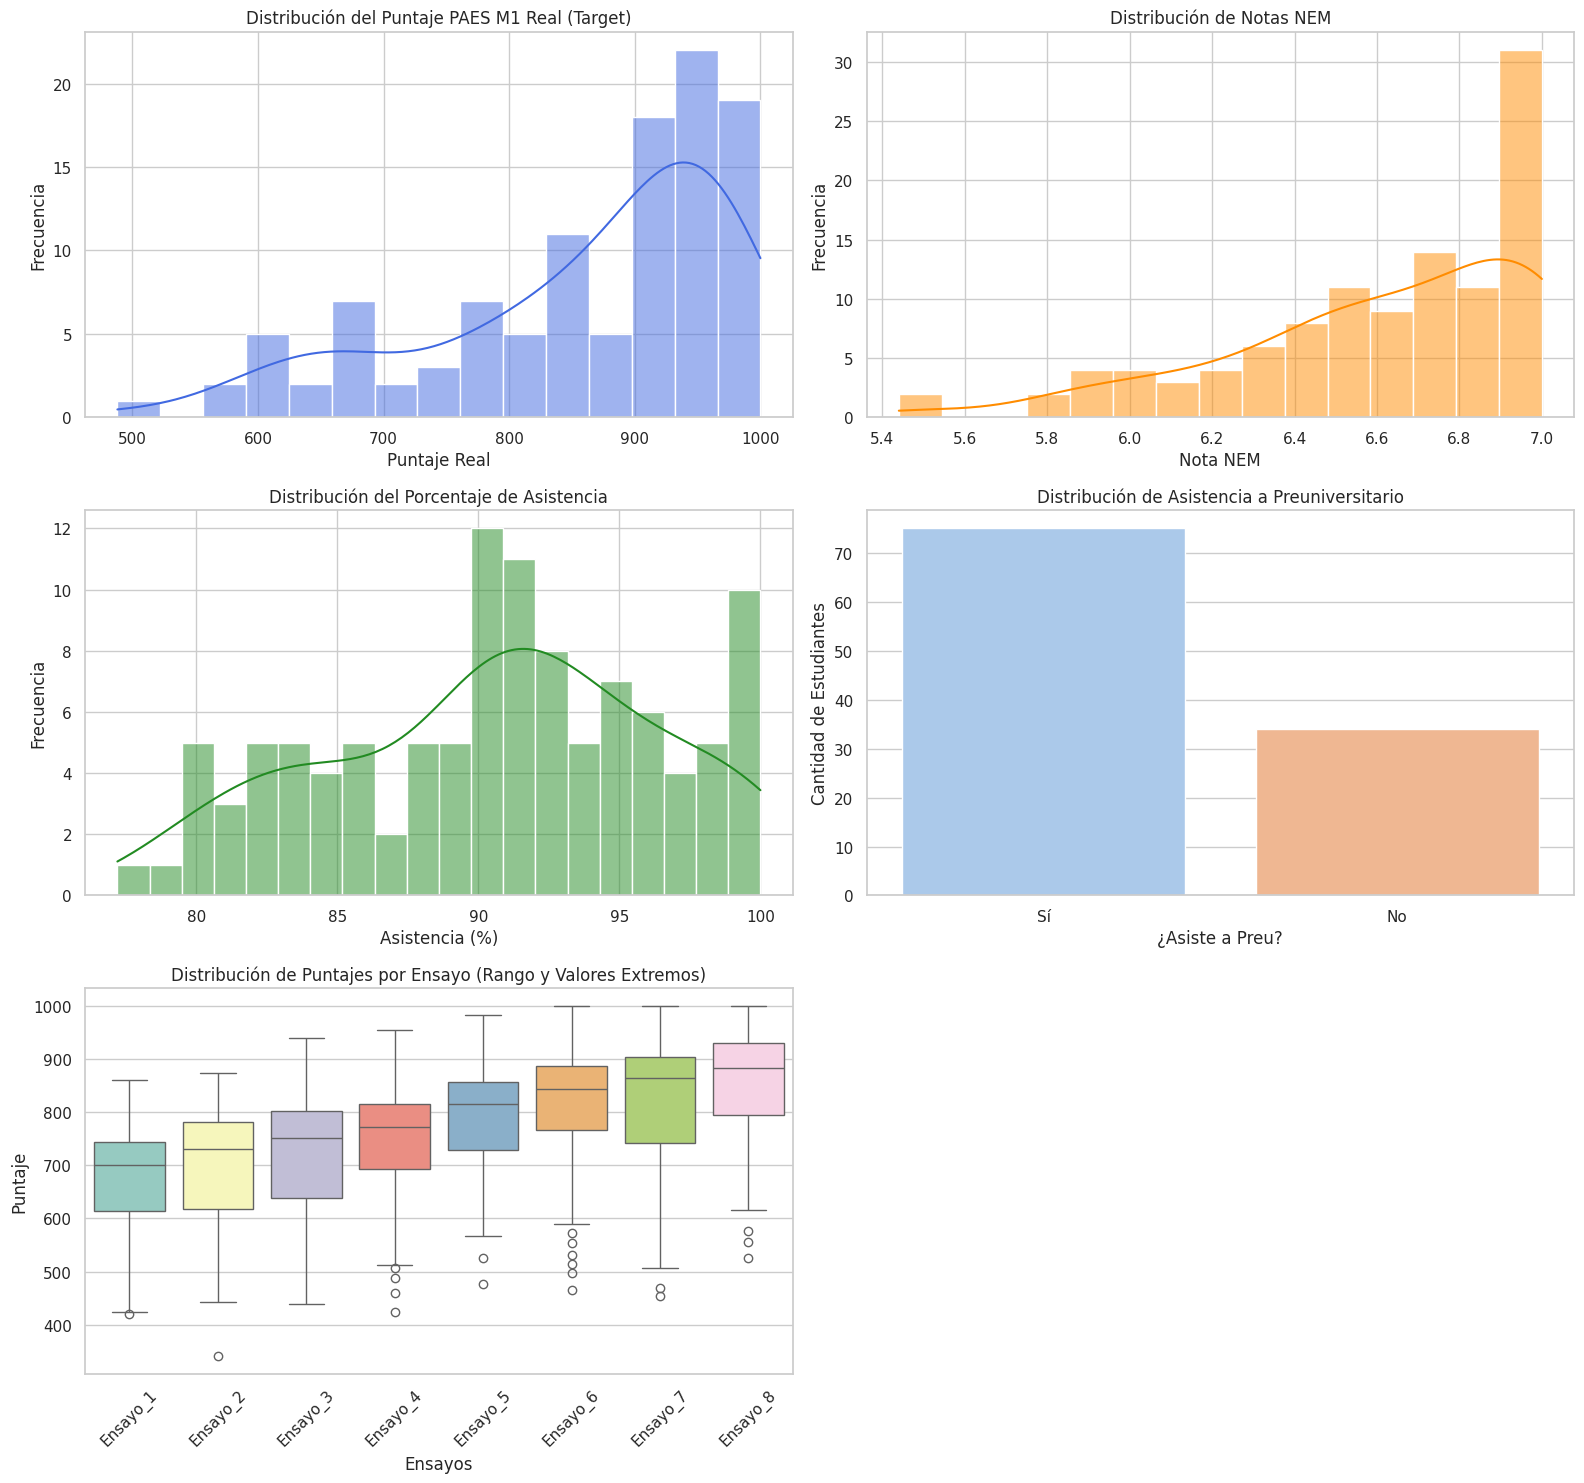

In [ ]:
# 5. Distribuciones univariantes
sns.set_theme(style="whitegrid", context="notebook")

# Crear una figura con una cuadrícula de gráficos (3 filas x 2 columnas)
fig, axes = plt.subplots(3, 2, figsize=(16, 15))

# 1. Distribución del Target (PAES_M1_Real)
# ¿Es simétrica o los alumnos tienden a sacar puntajes altos?
sns.histplot(df['PAES_M1_Real'], kde=True, ax=axes[0, 0], color='royalblue', bins=15)
axes[0, 0].set_title('Distribución del Puntaje PAES M1 Real (Target)')
axes[0, 0].set_xlabel('Puntaje Real')
axes[0, 0].set_ylabel('Frecuencia')

# 2. Distribución de Notas NEM
# ¿Dónde se concentra el grueso de las notas de los alumnos?
sns.histplot(df['Nota_NEM'], kde=True, ax=axes[0, 1], color='darkorange', bins=15)
axes[0, 1].set_title('Distribución de Notas NEM')
axes[0, 1].set_xlabel('Nota NEM')
axes[0, 1].set_ylabel('Frecuencia')

# 3. Distribución del Porcentaje de Asistencia
# ¿Hay "colas largas" hacia la izquierda indicando deserción o muy baja asistencia?
sns.histplot(df['Asistencia_Pct'], kde=True, ax=axes[1, 0], color='forestgreen', bins=20)
axes[1, 0].set_title('Distribución del Porcentaje de Asistencia')
axes[1, 0].set_xlabel('Asistencia (%)')
axes[1, 0].set_ylabel('Frecuencia')

# 4. Distribución de variable categórica (Preuniversitario)
# ¿Cómo es la proporción entre los que asisten y no asisten a preuniversitario?
sns.countplot(x='Preuniversitario', data=df, ax=axes[1, 1], palette='pastel')
axes[1, 1].set_title('Distribución de Asistencia a Preuniversitario')
axes[1, 1].set_xlabel('¿Asiste a Preu?')
axes[1, 1].set_ylabel('Cantidad de Estudiantes')

# 5. Evolución y valores extremos en los Ensayos (Boxplot)
# ¿Aumenta la mediana con cada ensayo? ¿Hay valores demasiado bajos/altos (outliers)?
ensayos_cols = ['Ensayo_1', 'Ensayo_2', 'Ensayo_3', 'Ensayo_4',
                'Ensayo_5', 'Ensayo_6', 'Ensayo_7', 'Ensayo_8']

sns.boxplot(data=df[ensayos_cols], ax=axes[2, 0], palette='Set3')
axes[2, 0].set_title('Distribución de Puntajes por Ensayo (Rango y Valores Extremos)')
axes[2, 0].set_xlabel('Ensayos')
axes[2, 0].set_ylabel('Puntaje')
axes[2, 0].tick_params(axis='x', rotation=45) # Rotar textos del eje X

# Eliminamos el gráfico vacío que sobra en la cuadrícula (fila 3, columna 2)
fig.delaxes(axes[2, 1])

plt.tight_layout()
plt.show()

### 📊 Conclusiones e Interpretaciones: Análisis Univariante (EDA)

#### 1. Sintesis Visual y Comportamiento de Variables
* **Puntaje PAES M1 Real (Target):** Presenta asimetría negativa severa con una fuerte concentración de puntajes sobre los 800 puntos y un pico de frecuencia entre 900 y 1000 puntos[cite: 1, 2].
* **Notas NEM:** Asimetría negativa coherente con el rendimiento general; la gran mayoría de las notas supera el 6.2 y se concentra entre 6.5 y 7.0[cite: 1].
* **Asistencia (%):** Alta concentración sobre el 80% de asistencia, pero presenta una cola larga a la izquierda con casos puntuales entre 30% y 70%[cite: 1].
* **Preuniversitario:** Variable categórica desbalanceada; la proporción de estudiantes que asiste a preuniversitario duplica a la de quienes no asisten[cite: 1].
* **Evolución de Ensayos:** Se evidencia una tendencia ascendente progresiva en las medianas del Ensayo 1 al Ensayo 8, junto con la presencia constante de valores atípicos (*outliers*) en el extremo inferior[cite: 1].

---

#### 2. Lineamientos para el Tratamiento de Datos (Data Preprocessing)
* **Imputación de Valores Faltantes (NaN):** No imputar ausencias con `0` ni con la media global[cite: 1]. Se recomienda usar el promedio individual del estudiante o un algoritmo de vecinos cercanos (`KNNImputer`)[cite: 1].
* **Manejo de Outliers:** Mantener los puntajes atípicos bajos en los ensayos, ya que reflejan variaciones reales del desempeño del estudiante[cite: 1].
* **Prevención del Sobreajuste (*Overfitting*):** Debido al alto sesgo de puntajes hacia el rango superior, se debe implementar validación cruzada (*K-Fold Cross-Validation*) y métricas de error robustas[cite: 1].

## 6. Relación entre variables numéricas (Análisis Bivariante)

Una vez comprendidas las distribuciones individuales, el siguiente paso lógico es explorar cómo se relacionan entre sí las variables numéricas más críticas de nuestro dataset. En el contexto educativo, esto se traduce en buscar correlaciones visuales que nos ayuden a predecir el éxito.

Esta fase del EDA responde a interrogantes como:
- **¿A mayor compromiso (Asistencia), mejor resultado final (PAES Real)?** El gráfico de dispersión (*scatterplot*) nos permite observar si existe una tendencia ascendente, o si por el contrario, los puntos están dispersos al azar, sugiriendo que la asistencia no es un factor determinante por sí solo.
- **¿La relación entre las notas del colegio (NEM) y los ensayos parece ser lineal?** Mediante la línea de regresión, podemos evaluar si un incremento constante en el NEM se asocia con un incremento proporcional en los ensayos preparatorios.
- **¿Existen anomalías (*Outliers*)?** Estos gráficos son vitales para identificar estudiantes atípicos; por ejemplo, casos puntuales (puntos alejados de la tendencia central) de alumnos con un porcentaje de asistencia muy bajo que aun así logran puntajes excepcionalmente altos, o viceversa.

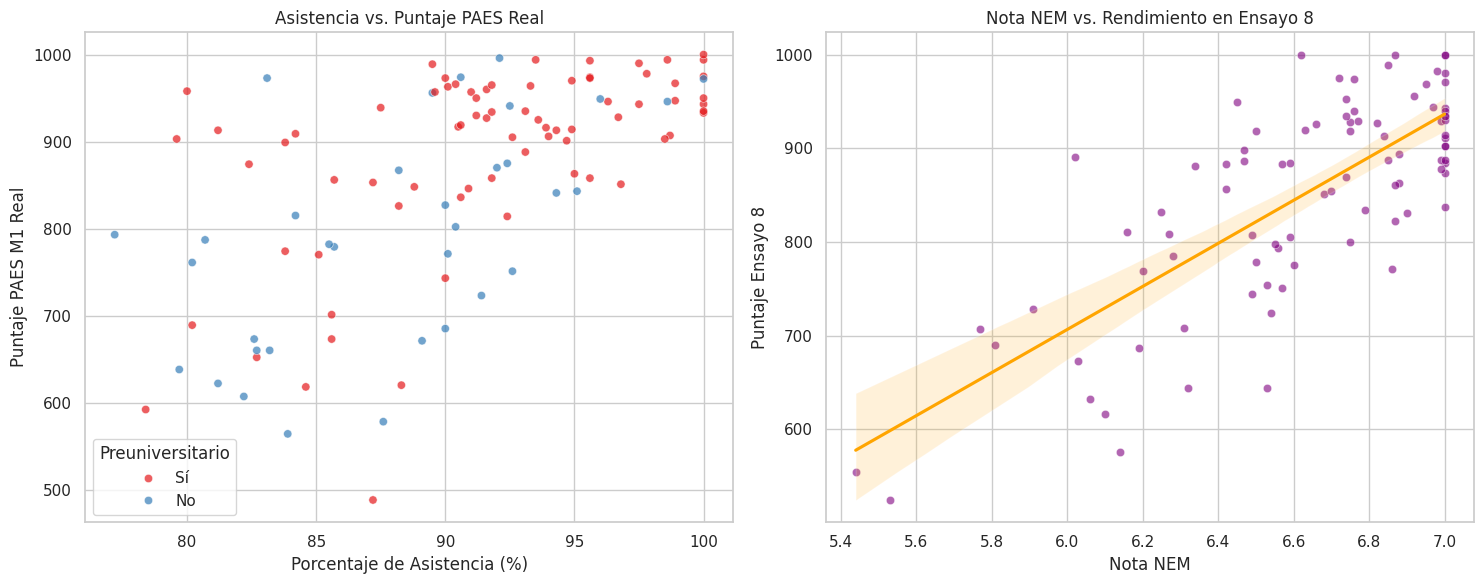

In [ ]:
# 6. Relación entre variables numéricas (Análisis Bivariante)
# Evaluamos cómo interactúan dos variables clave para entender su posible correlación.

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Gráfico 1: Asistencia vs. Puntaje Real (Target)
# ¿Existe una tendencia lineal visible?
sns.scatterplot(
    data=df,
    x='Asistencia_Pct',
    y='PAES_M1_Real',
    hue='Preuniversitario', # Añadimos color para ver si el preuniversitario agrupa los puntos
    palette='Set1',
    alpha=0.7,
    ax=axes[0]
)
axes[0].set_title('Asistencia vs. Puntaje PAES Real')
axes[0].set_xlabel('Porcentaje de Asistencia (%)')
axes[0].set_ylabel('Puntaje PAES M1 Real')

# Gráfico 2: Nota NEM vs. Último Ensayo (Ensayo_8)
# ¿Las notas del colegio reflejan el rendimiento final de preparación?
sns.scatterplot(
    data=df,
    x='Nota_NEM',
    y='Ensayo_8',
    color='purple',
    alpha=0.6,
    ax=axes[1]
)
# Agregamos una línea de tendencia lineal simple (regresión)
sns.regplot(
    data=df,
    x='Nota_NEM',
    y='Ensayo_8',
    scatter=False,
    color='orange',
    ax=axes[1]
)
axes[1].set_title('Nota NEM vs. Rendimiento en Ensayo 8')
axes[1].set_xlabel('Nota NEM')
axes[1].set_ylabel('Puntaje Ensayo 8')

plt.tight_layout()
plt.show()

### Conclusiones: Relación entre Variables Numéricas
*   **Asistencia y Puntaje:** Existe una tendencia donde un mayor porcentaje de asistencia se asocia con mejores puntajes en la PAES real[cite: 2].
*   **NEM y Ensayos:** Se observa una relación lineal positiva entre las notas del colegio (NEM) y el rendimiento en los ensayos, indicando que a mejor NEM, mejor puntaje en el ensayo[cite: 2].
*   **Anomalías (Outliers):** Se identifican casos atípicos, como estudiantes con baja asistencia pero altos puntajes, o viceversa, que escapan al patrón general[cite: 2].

## 7. Matriz de Correlación (Heatmap)
Tras analizar las relaciones bivariadas, la matriz de correlación de Pearson nos proporciona una visión global de las interacciones lineales entre todas las variables numéricas. Nos permite confirmar qué variables (como `Nota_NEM`, `Asistencia_Pct` o los `Ensayos`) actúan como mejores predictores para nuestro objetivo (`PAES_M1_Real`).

### 📊 Conclusiones:
*   **Predictores Principales:** Los ensayos finales (`Ensayo_7`, `Ensayo_8`) y el `NEM` suelen mostrar la mayor correlación positiva con el puntaje `PAES_M1_Real`.
*   **Correlación Interna (Multicolinealidad):** Es esperable observar una alta correlación entre los distintos ensayos, lo que refleja consistencia en el proceso de preparación del estudiante.
*   **Factor Asistencia:** La `Asistencia_Pct` generalmente presenta una correlación positiva (aunque a veces moderada), reafirmando que el compromiso sostenido influye linealmente en el rendimiento.

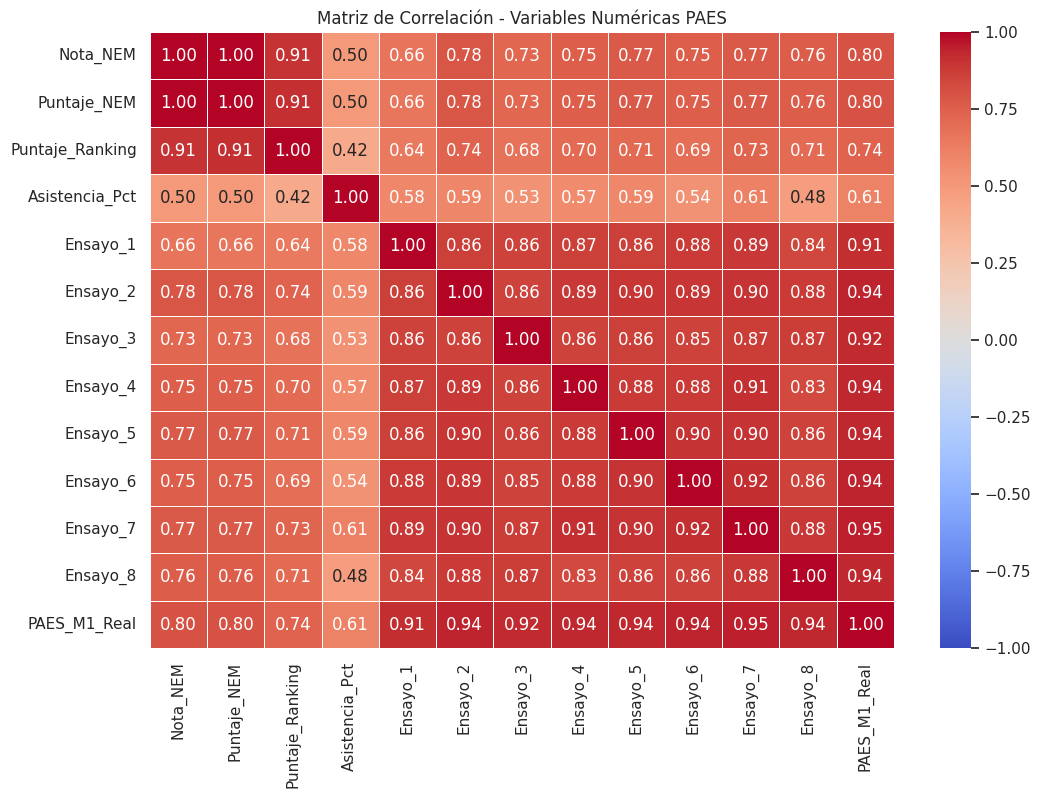

In [ ]:
# 7. Matriz de Correlación (Heatmap)
# Seleccionamos solo las variables numéricas del dataset df
vars_num = df.select_dtypes(include=['float64', 'int64'])

# Calculamos la matriz de correlación de Pearson
corr_matrix = vars_num.corr()

# Creamos la visualización (Heatmap)
plt.figure(figsize=(12, 8))
sns.heatmap(
    corr_matrix,
    annot=True,       # Muestra el valor de correlación en la celda
    fmt=".2f",        # Formato de dos decimales
    cmap="coolwarm",  # Paleta de colores intuitiva (rojo=positiva, azul=negativa)
    vmin=-1,          # Límite inferior de la escala
    vmax=1,           # Límite superior de la escala
    linewidths=0.5
)
plt.title('Matriz de Correlación - Variables Numéricas PAES')
plt.show()

📊 **Conclusiones e Interpretación: **

Matriz de CorrelaciónPoder Predictivo de los Ensayos: Se observa que los ensayos más recientes, particularmente el Ensayo_7 y el Ensayo_8, son los que presentan la correlación positiva más fuerte con el PAES_M1_Real. Esto indica que el rendimiento en la recta final de la preparación es el mejor predictor lineal del puntaje real en la prueba.   Consistencia Interna (Multicolinealidad): La alta correlación positiva entre los diferentes ensayos (por ejemplo, entre Ensayo_1 y Ensayo_2, o Ensayo_7 y Ensayo_8) refleja una consistencia en el rendimiento de los estudiantes a lo largo del tiempo. Quien rinde bien en un ensayo, tiende a rendir bien en los siguientes.   Importancia del NEM: La Nota_NEM muestra una correlación positiva fuerte con el PAES_M1_Real, confirmando que el desempeño académico previo es un indicador sólido del resultado final.   El Factor Asistencia: La Asistencia_Pct presenta una correlación positiva con los puntajes, aunque de magnitud moderada. Esto sugiere que, si bien una mayor asistencia acompaña mejores resultados, por sí sola podría no ser el predictor más fuerte desde una perspectiva estrictamente lineal, lo que invita a explorar posibles relaciones no lineales más adelante.  

### 8. Detección sencilla de Outliers con IQR

Un valor extremo (outlier) no siempre es un error; puede representar un caso poco frecuente pero válido[cite: 1]. Sin embargo, detectarlos es crucial para decidir si requieren revisión, si deben ser comentados o mantenidos en el análisis[cite: 1].

Para una detección sencilla y robusta, aplicaremos la regla del rango intercuartílico (IQR):
1. **Q1 y Q3**: Calcularemos el primer (25%) y tercer (75%) cuartil.
2. **IQR**: Obtendremos el rango intercuartílico (Q3 - Q1).
3. **Límites**: Definiremos los límites inferior ($Q1 - 1.5 \times IQR$) y superior ($Q3 + 1.5 \times IQR$).
Los valores fuera de estos límites se considerarán valores atípicos.

In [ ]:
# 8. Detección sencilla de Outliers con IQR

# Seleccionamos solo las columnas numéricas relevantes
columnas_numericas = df.select_dtypes(include=[np.number]).columns

def detectar_outliers_iqr(dataframe, columna):
    """
    Detecta outliers usando IQR y devuelve un df filtrado con esos registros.
    """
    Q1 = dataframe[columna].quantile(0.25)
    Q3 = dataframe[columna].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    return dataframe[(dataframe[columna] < limite_inferior) | (dataframe[columna] > limite_superior)]

print("--- Resumen de Outliers detectados (IQR) ---")
for col in columnas_numericas:
    outliers_df = detectar_outliers_iqr(df, col)
    if not outliers_df.empty:
        print(f"Variable '{col}': {len(outliers_df)} outliers.")
    else:
        print(f"Variable '{col}': Sin outliers.")

--- Resumen de Outliers detectados (IQR) ---
Variable 'Nota_NEM': 2 outliers.
Variable 'Puntaje_NEM': 2 outliers.
Variable 'Puntaje_Ranking': 16 outliers.
Variable 'Asistencia_Pct': Sin outliers.
Variable 'Ensayo_1': 1 outliers.
Variable 'Ensayo_2': 1 outliers.
Variable 'Ensayo_3': Sin outliers.
Variable 'Ensayo_4': 4 outliers.
Variable 'Ensayo_5': 2 outliers.
Variable 'Ensayo_6': 6 outliers.
Variable 'Ensayo_7': 2 outliers.
Variable 'Ensayo_8': 3 outliers.
Variable 'PAES_M1_Real': 1 outliers.


### 📊 11. Síntesis Final del Mini-Caso y Tratamiento de Datos

#### 1. Síntesis del EDA
* **¿Qué hemos visto?:** Asimetría en variables estructurales (Puntaje PAES Real y NEM) y presencia de valores nulos (`NaN`) en ensayos debido al ausentismo.
* **¿Qué variables parecen importantes?:** Alta correlación entre el NEM y los ensayos, junto con una tendencia de mayor puntaje PAES M1 a mayor porcentaje de asistencia.
* **¿Qué limitaciones aparecen?:** Desbalance en la variable `Preuniversitario`, fuerte sesgo de puntajes hacia el tramo superior (>800 pts) y presencia de *outliers* bajos en ensayos.
* **¿Qué siguiente paso tendría sentido?:** Definir la estrategia de imputación y preparar el conjunto de datos (*split* train/test) para el modelamiento predictivo.

---

#### 2. Justificación y Plan de Tratamiento de Datos

* **Imputación de Valores Faltantes (`NaN` en Ensayos):**
  * **Decisión:** Imputar mediante el promedio individual de los ensayos rendidos por cada estudiante (o `KNNImputer`).
  * **Justificación:** Respeta la trayectoria y perfil del alumno sin sesgar la distribución global ni penalizar erróneamente con cero.

* **Manejo de Valores Atípicos (*Outliers*):**
  * **Decisión:** Mantener intactos los puntajes atípicos bajos en los ensayos.
  * **Justificación:** Representan fluctuaciones reales del rendimiento escolar y evitan la eliminación artificial de variabilidad del entorno educativo.

* **Estrategia de Ejecución:**
  * **Decisión:** Aplicar el tratamiento dentro de un `Pipeline` inmediatamente después de dividir el dataset en *train* y *test*.
  * **Justificación:** Previene la fuga de información (*data leakage*) hacia el conjunto de evaluación.

In [ ]:


# Identificamos las columnas que corresponden a los ensayos
columnas_ensayos = [col for col in df.columns if col.startswith('Ensayo_')]

# Imputación: Rellenar NaN en ensayos con el promedio individual del estudiante en los demás ensayos
# Calculamos la media por fila (axis=1), ignorando los NaN actuales
promedios_individuales = df[columnas_ensayos].mean(axis=1)

# Aplicamos la imputación
for col in columnas_ensayos:
    # Rellenamos los NaN en cada columna de ensayo con el promedio individual correspondiente
    df[col] = df[col].fillna(promedios_individuales)

# Verificación rápida
print("Valores nulos tras la imputación en ensayos:")
print(df[columnas_ensayos].isnull().sum())

# Opcional: Si un estudiante no rindió ningún ensayo, el promedio será NaN.
# En ese caso remoto, podríamos usar un KNNImputer o la mediana global,
# pero la imputación individual cubre la gran mayoría de ausencias comunes.

Valores nulos tras la imputación en ensayos:
Ensayo_1    0
Ensayo_2    0
Ensayo_3    0
Ensayo_4    0
Ensayo_5    0
Ensayo_6    0
Ensayo_7    0
Ensayo_8    0
dtype: int64
